In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from transformers import CLIPTokenizer
from dataclasses import dataclass
from torch.utils.data import Dataset
import os
import torchvision.transforms as T
import torch.nn.functional as F
from PIL import Image
import torch
import pandas as pd
import requests
from io import BytesIO
from pathlib import Path
from tqdm import tqdm
import random

c:\files\PracticalML\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Using device: cuda


In [ ]:
# Load NASA APOD dataset and filter only images with explanations
csv_path = "/kaggle/input/nasa-astronomy-picture-of-the-day-apod-extended/nasa-apod-dataset.csv"
df_temp = pd.read_csv(csv_path, sep=';')
df_filtered = df_temp[(df_temp['media_type'] == 'image') & (df_temp['explanation'].notna())]

# Limit dataset size for training
# half_size = len(df_filtered) // 3
half_size = 500

In [ ]:
# Load CLIP tokenizer for text encoding
tokenizer = CLIPTokenizer.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="tokenizer"
)

In [ ]:
# Training configuration dataclass
@dataclass
class TrainingConfig:
    image_size = 512  # Input image resolution
    train_batch_size = 12 # Batch size for training
    eval_batch_size = 8   # Batch size for evaluation
    num_epochs = 5  # Number of training epochs
    gradient_accumulation_steps = 4  # Steps to accumulate gradients
    learning_rate = 1e-5  # Learning rate for optimizer
    lr_warmup_steps = 300 # Warmup steps for scheduler
    save_image_epochs = 1  # Save sample images every N epochs
    save_model_epochs = 1  # Save model checkpoint every N epochs
    mixed_precision = "fp16"   # Use mixed precision training
    output_dir = "/kaggle/working/ddpm-NASA-inpainting-512"
    push_to_hub = False
    hub_private_repo = False
    overwrite_output_dir = True
    seed = 0

config = TrainingConfig()

In [ ]:
# Custom Dataset for inpainting task
class InpaintingDataset(Dataset):
    def __init__(self, csv_path, image_size=512, cache_dir="cached_images", limit=None, mask_size_range=(32, 64), cache_latents=False, latents_cache_dir="cached_latents"):
        self.image_size = image_size
        self.mask_size_range = mask_size_range
        self.cache_latents = cache_latents
        self.latents_cache_dir = latents_cache_dir
        self.latents_cache = {}  # Cache for precomputed latents
        
        # Load and filter dataset
        df = pd.read_csv(csv_path, sep=';')
        df = df[df['media_type'] == 'image']
        df = df.dropna(subset=['media_url', 'explanation'])
        
        # Sort by date (newest first)
        if 'date' in df.columns:
            df['date'] = pd.to_datetime(df['date'])
            df = df.sort_values('date', ascending=False)
        
        if limit is not None:
            df = df.head(limit)
        
        self.data = df.reset_index(drop=True)
        
        # Setup image cache directory
        self.cache_dir = Path(cache_dir)
        self.cache_dir.mkdir(exist_ok=True)
        
        # Image transforms: resize and convert to tensor
        self.transform = T.Compose([
            T.Resize((image_size, image_size)),
            T.ToTensor(),
        ])
        
        # Mask transform with nearest neighbor interpolation
        self.mask_transform = T.Compose([
            T.Resize((image_size, image_size), interpolation=T.InterpolationMode.NEAREST),
            T.ToTensor(),
        ])

    def _download_image(self, url, idx):
        cache_path = self.cache_dir / f"{idx}.jpg"
        
        # Return cached image if exists
        if cache_path.exists():
            return Image.open(cache_path).convert("RGB")
        
        # Download and cache image
        try:
            response = requests.get(url, timeout=10)
            response.raise_for_status()
            image = Image.open(BytesIO(response.content)).convert("RGB")
            image.save(cache_path, "JPEG")
            return image
        except Exception as e:
            print(f"Error downloading {url}: {e}")
            return None

    def _generate_random_square_mask(self, image_size, num_squares=3, seed=None):
        if seed is not None:
            random.seed(seed)
            np.random.seed(seed)
        
        # Create empty mask
        mask = Image.new('L', (image_size, image_size), 0)
        mask_array = np.array(mask)
        
        # Add random squares to mask
        for i in range(num_squares):
            if seed is not None:
                random.seed(seed + i * 1000)
                np.random.seed(seed + i * 1000)
            
            mask_size = random.randint(self.mask_size_range[0], self.mask_size_range[1])
            x = random.randint(0, max(1, image_size - mask_size))
            y = random.randint(0, max(1, image_size - mask_size))
            
            mask_array[y:y+mask_size, x:x+mask_size] = 255
        
        mask = Image.fromarray(mask_array)
        return mask

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        
        url = row['media_url']
        image = self._download_image(url, idx)
        
        # Create black image if download failed
        if image is None:
            image = Image.new('RGB', (self.image_size, self.image_size), color='black')
        
        image_tensor = self.transform(image)

        # Generate deterministic mask based on index
        mask = self._generate_random_square_mask(self.image_size, num_squares=3, seed=idx)
        mask_tensor = self.mask_transform(mask)
        mask_tensor = (mask_tensor > 0.5).float()

        result = {
            "pixel_values": image_tensor,
            "mask": mask_tensor,
            "index": idx,
        }
        
        # Add cached latents if available
        if self.cache_latents and idx in self.latents_cache:
            result["latents"] = self.latents_cache[idx]["latents"]
            result["masked_latents"] = self.latents_cache[idx]["masked_latents"]
        
        return result

In [ ]:
from diffusers import StableDiffusionInpaintPipeline

model_path = "runwayml/stable-diffusion-inpainting"

pipe = StableDiffusionInpaintPipeline.from_pretrained(
    model_path,
    torch_dtype=torch.float16  # Use FP16 for faster inference
).to(device)

# Extract UNet for fine-tuning
unet = pipe.unet

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]An error occurred while trying to fetch C:\Users\VTvol\.cache\huggingface\hub\models--runwayml--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\vae: Error no file named diffusion_pytorch_model.safetensors found in directory C:\Users\VTvol\.cache\huggingface\hub\models--runwayml--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Loading pipeline components...:  29%|██▊       | 2/7 [00:00<00:01,  3.91it/s]An error occurred while trying to fetch C:\Users\VTvol\.cache\huggingface\hub\models--runwayml--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\unet: Error no file named diffusion_pytorch_model.safetensors found in directory C:\Users\VTvol\.cache\huggingface\hub\models--runwayml--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aed

In [ ]:
# Setup LoRA (Low-Rank Adaptation) for efficient fine-tuning
from peft import LoraConfig, get_peft_model

# LoRA config: only train attention layers with low-rank matrices
lora_config = LoraConfig(
    r=16,                        # Rank of LoRA matrices
    lora_alpha=32,               # Scaling factor
    init_lora_weights="gaussian",
    target_modules=["to_q", "to_k", "to_v", "to_out.0"],  # Target attention layers
)

# Enable memory-efficient training
unet.enable_gradient_checkpointing()

# Freeze all base model parameters
for param in unet.parameters():
    param.requires_grad = False

# Apply LoRA to UNet
unet = get_peft_model(unet, lora_config)
unet.print_trainable_parameters()

trainable params: 3,188,736 || all params: 862,724,100 || trainable%: 0.3696


In [ ]:
# Load VAE for image encoding/decoding
from diffusers import AutoencoderKL

vae = AutoencoderKL.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="vae"
)

# VAE is frozen during training
vae.eval()
vae.requires_grad_(False)

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

AutoencoderKL(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (c

In [ ]:
# Load CLIP text encoder for prompt conditioning
from transformers import CLIPTextModel

text_encoder = CLIPTextModel.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="text_encoder"
)

# Text encoder is frozen during training
text_encoder.eval()
text_encoder.requires_grad_(False)

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

CLIPTextModel(
  (text_model): CLIPTextTransformer(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 768)
      (position_embedding): Embedding(77, 768)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e

In [ ]:
# Load noise scheduler for diffusion process
from diffusers import DDPMScheduler

noise_scheduler = DDPMScheduler.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="scheduler"
)
print(f"Scheduler num_train_timesteps: {noise_scheduler.config.num_train_timesteps}")
print(f"Scheduler beta_schedule: {noise_scheduler.config.beta_schedule}")


scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

Scheduler num_train_timesteps: 1000
Scheduler beta_schedule: scaled_linear


In [ ]:
# Initialize dataset
dataset = InpaintingDataset(
    csv_path=csv_path,
    image_size=config.image_size,
    limit=half_size,
    mask_size_range=(32, 64)  # Random mask size range
)

# Empty text tokens (unconditional generation)
empty_input_ids = torch.zeros((1, 77), dtype=torch.long)

print(f"Dataset size: {len(dataset)}")

# Verify sample shapes
sample = dataset[0]
print(f"Sample image shape: {sample['pixel_values'].shape}")
print(f"Sample mask shape: {sample['mask'].shape}")

torch.cuda.empty_cache() if torch.cuda.is_available() else None

Dataset size: 500
Sample image shape: torch.Size([3, 512, 512])
Sample mask shape: torch.Size([1, 512, 512])


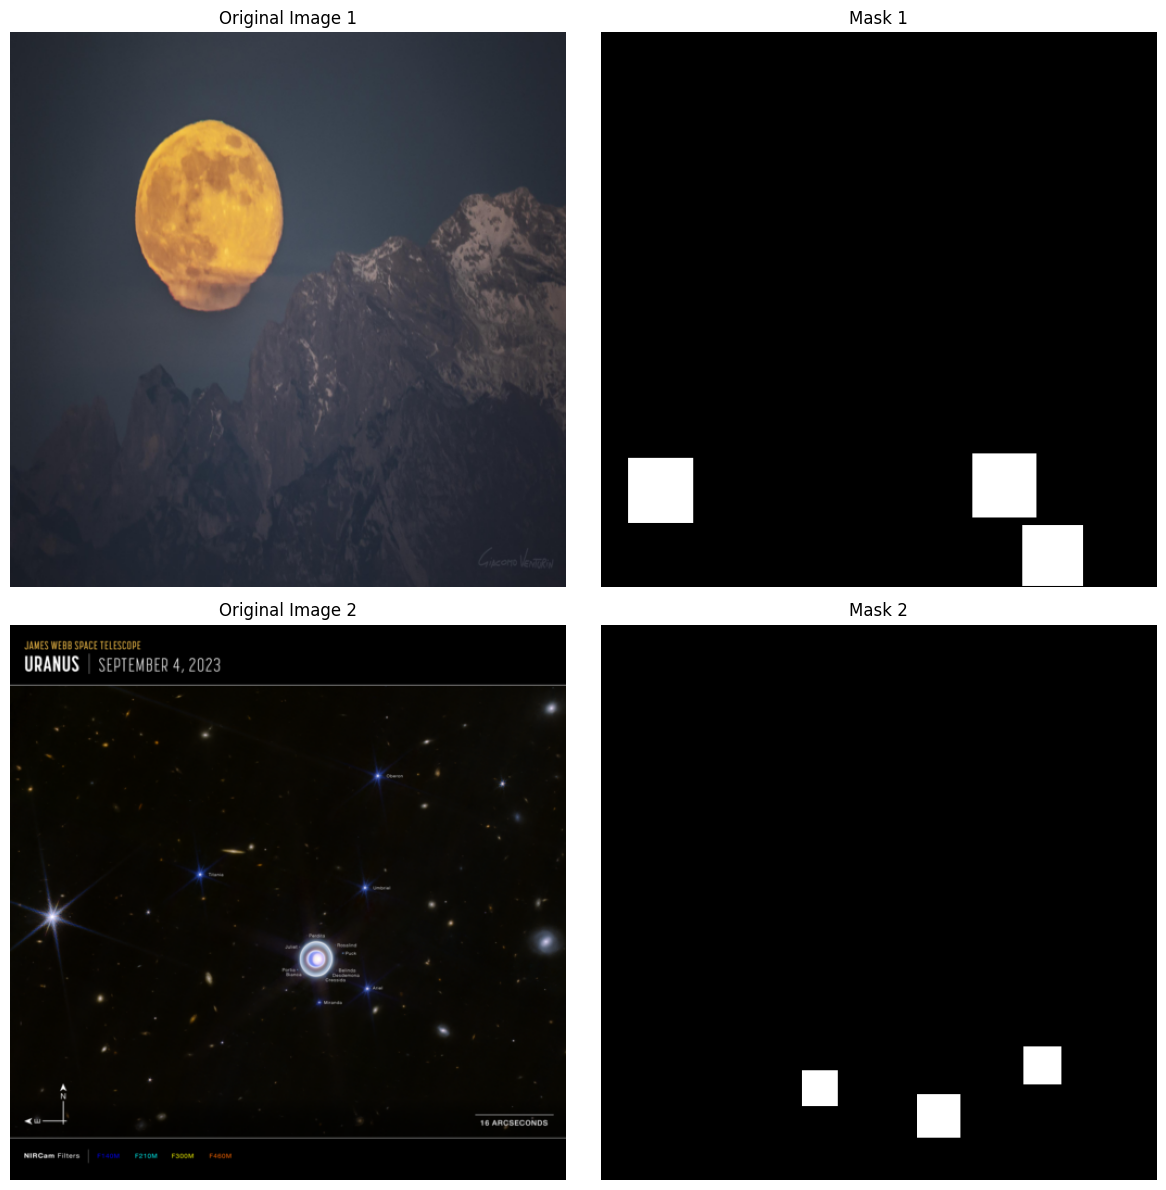

In [ ]:
# Visualize sample images and their masks
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for row in range(2):
    idx = row
    sample = dataset[idx]
    
    # Convert tensors to numpy for visualization
    image_tensor = sample["pixel_values"]
    mask_tensor = sample["mask"]
    
    image = image_tensor.permute(1, 2, 0).numpy()
    mask = mask_tensor.squeeze(0).numpy()
    
    # Display original image
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original Image {idx + 1}")
    axes[row, 0].axis('off')
    
    # Display mask
    mask_rgb = np.stack([mask, mask, mask], axis=-1)
    axes[row, 1].imshow(mask_rgb)
    axes[row, 1].set_title(f"Mask {idx + 1}")
    axes[row, 1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from concurrent.futures import ThreadPoolExecutor, as_completed

vae_to_device = vae.to(device)
vae_to_device.eval()

batch_size = 12
image_cache_dir = dataset.cache_dir

def load_image_and_mask(idx):
    try:
        sample = dataset[idx]
        image_tensor = sample["pixel_values"]
        mask_tensor = sample["mask"]
        return idx, image_tensor, mask_tensor
    except Exception as e:
        print(f"Error loading sample {idx}: {e}")
        return idx, None, None

# Process images in batches
for batch_start in tqdm(range(0, len(dataset), batch_size), desc="Processing batches"):
    batch_end = min(batch_start + batch_size, len(dataset))
    batch_indices = list(range(batch_start, batch_end))
    
    batch_images = []
    batch_masks = []
    valid_indices = []
    
    # Load images in parallel using thread pool
    with ThreadPoolExecutor(max_workers=8) as executor:
        futures = {executor.submit(load_image_and_mask, idx): idx for idx in batch_indices}
        for future in as_completed(futures):
            idx, image_tensor, mask_tensor = future.result()
            if image_tensor is not None and mask_tensor is not None:
                batch_images.append(image_tensor)
                batch_masks.append(mask_tensor)
                valid_indices.append(idx)
    
    if not batch_images:
        continue
    
    # Encode images to latent space
    with torch.no_grad():
        batch_image_tensor = torch.stack(batch_images).to(device)
        batch_mask_tensor = torch.stack(batch_masks).to(device)
        
        # Encode original images to latents
        latents = vae_to_device.encode(batch_image_tensor * 2.0 - 1.0).latent_dist.sample()
        latents = latents * vae_to_device.config.scaling_factor
        latents = latents.cpu()
        
        # Create masked images and encode them
        masked_images = batch_image_tensor * (1 - batch_mask_tensor)
        
        masked_latents = vae_to_device.encode(masked_images * 2.0 - 1.0).latent_dist.sample()
        masked_latents = masked_latents * vae_to_device.config.scaling_factor
        masked_latents = masked_latents.cpu()
        
        # Cache latents for each sample
        for i, idx in enumerate(valid_indices):
            dataset.latents_cache[idx] = {
                "latents": latents[i],
                "masked_latents": masked_latents[i]
            }
        
        # Free GPU memory
        del batch_image_tensor, batch_mask_tensor, masked_images
        del latents, masked_latents
        torch.cuda.empty_cache()

# Enable cached latents in dataset
dataset.cache_latents = True
torch.cuda.empty_cache()
print(f"Precached {len(dataset.latents_cache)} latents")

Processing batches:  64%|██████▍   | 27/42 [04:52<02:45, 11.02s/it]

Error downloading https://apod.nasa.gov/apod/image/2301/RockyRed7_DeepAI_960.jpg: 404 Client Error: Not Found for url: https://apod.nasa.gov/apod/image/2301/RockyRed7_DeepAI_960.jpg


Processing batches: 100%|██████████| 42/42 [07:29<00:00, 10.70s/it]

Precached 500 latents


In [ ]:
# Create DataLoader for training
train_dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=config.train_batch_size,
    shuffle=True,  # Shuffle for training
    num_workers=4,  # Parallel data loading
    pin_memory=True if torch.cuda.is_available() else False,
    persistent_workers=True, # Keep workers alive between epochs
)

In [ ]:
# Verify encoder dimensions and latent shapes
text_hidden = text_encoder.config.hidden_size
print("text_encoder.config.hidden_size:", text_encoder.config.hidden_size)

vae.to(device)
sample = dataset[0]
sample_image = sample["pixel_values"].unsqueeze(0).to(device)
sample_mask = sample["mask"].unsqueeze(0).to(device)

# Test VAE encoding to verify latent dimensions
with torch.no_grad():
    latent_image = vae.encode(sample_image * 2.0 - 1.0).latent_dist.sample()
    latent_image = latent_image * vae.config.scaling_factor
    print(f"Latent image shape: {latent_image.shape}")
    print(f"Mask shape: {sample_mask.shape}")

# Cleanup
del sample_image, sample_mask, latent_image
torch.cuda.empty_cache() if torch.cuda.is_available() else None

text_encoder.config.hidden_size: 768
Latent image shape: torch.Size([1, 4, 64, 64])
Mask shape: torch.Size([1, 1, 512, 512])


In [ ]:
from diffusers.optimization import get_cosine_schedule_with_warmup

# Only optimize LoRA parameters
trainable_params = list(filter(lambda p: p.requires_grad, unet.parameters()))
optimizer = torch.optim.AdamW(trainable_params, lr=config.learning_rate)

# Schedule with warmup for stable training
lr_scheduler = get_cosine_schedule_with_warmup(
    optimizer=optimizer,
    num_warmup_steps=config.lr_warmup_steps,
    num_training_steps=(len(train_dataloader) * config.num_epochs),
)

print(f"Optimizer initialized with {len(trainable_params)} trainable parameter groups")
print(f"LR scheduler: {config.lr_warmup_steps} warmup steps, {len(train_dataloader) * config.num_epochs} total steps")

Optimizer initialized with 256 trainable parameter groups
LR scheduler: 300 warmup steps, 210 total steps


In [ ]:
from diffusers.utils import make_image_grid

def evaluate(config, epoch, model, text_encoder, noise_scheduler, vae, dataset):
    # Select test samples from dataset
    test_indices = [0, 100, 500, 1000, 2000] if len(dataset) > 2000 else [0, len(dataset)//4, len(dataset)//2]
    test_indices = [i for i in test_indices if i < len(dataset)]
    
    # Set all models to eval mode
    model.eval()
    text_encoder.eval()
    vae.eval()
    
    pil_images = []
    masked_pil_images = []
    test_prompts = []
    
    model_device = next(model.parameters()).device
    model_dtype = next(model.parameters()).dtype

    # Handle DataParallel wrapped models
    model_base = model.module if hasattr(model, 'module') else model
    text_encoder_base = text_encoder.module if hasattr(text_encoder, 'module') else text_encoder
    vae_base = vae.module if hasattr(vae, 'module') else vae
    
    vae_base.to(model_device)
    text_encoder_base.to(model_device)
    vae_base.eval()
    text_encoder_base.eval()
    model_base.eval()
    
    # Empty prompt for unconditional generation
    empty_input_ids = torch.zeros((1, 77), dtype=torch.long).to(model_device)
    
    for idx in test_indices:
        sample = dataset[idx]
        image = sample["pixel_values"].unsqueeze(0).to(model_device, dtype=model_dtype)
        mask = sample["mask"].unsqueeze(0).to(model_device, dtype=model_dtype)
        mask = (mask > 0.5).float()
        input_ids = empty_input_ids

        # Create masked image for visualization
        masked_image = image * (1 - mask)
        masked_image_np = masked_image.cpu().permute(0, 2, 3, 1).numpy()[0]
        masked_image_np = (masked_image_np * 255).round().astype("uint8")
        masked_pil_images.append(Image.fromarray(masked_image_np))
        
        with torch.no_grad():
            # Encode images to latent space
            latent_image = vae_base.encode((image * 2.0 - 1.0).float()).latent_dist.sample()
            latent_image = latent_image * vae_base.config.scaling_factor
            
            latent_masked = vae_base.encode((masked_image * 2.0 - 1.0).float()).latent_dist.sample()
            latent_masked = latent_masked * vae_base.config.scaling_factor

            # Resize mask to latent dimensions
            mask_resized = F.interpolate(mask, size=(64, 64), mode="nearest")
            mask_resized = (mask_resized > 0.5).float()
            mask_resized = mask_resized.to(model_device, dtype=model_dtype)

            latent_image = latent_image.to(model_device, dtype=model_dtype)
            latent_masked = latent_masked.to(model_device, dtype=model_dtype)

            # Get text embeddings
            encoder_hidden_states = text_encoder_base(input_ids).last_hidden_state
            encoder_hidden_states = encoder_hidden_states.to(model_device, dtype=model_dtype)
            
            noise = torch.randn_like(latent_image)

            # Denoising loop
            noise_scheduler.set_timesteps(50)
            latents = noise_scheduler.add_noise(latent_image, noise, noise_scheduler.timesteps[0])
            latents = latent_image * (1 - mask_resized) + latents * mask_resized
            
            for t in noise_scheduler.timesteps:
                # Concatenate latents, masked latents, and mask
                latent_model_input = torch.cat([latents, latent_masked, mask_resized], dim=1)
                
                # Predict noise
                noise_pred = model_base(
                    latent_model_input,
                    timestep=t.to(model_device),
                    encoder_hidden_states=encoder_hidden_states,
                    return_dict=False
                )[0]
                
                # Denoise step
                latents = noise_scheduler.step(noise_pred, t, latents).prev_sample
                
                # Keep original content outside mask
                noisy_latent_image = noise_scheduler.add_noise(latent_image, noise, t)
                latents = latents * mask_resized + noisy_latent_image * (1 - mask_resized)
            
            # Decode latents to image
            latents = latents / vae_base.config.scaling_factor
            latents_for_decode = latents.to(torch.float32)
            decoded_image = vae_base.decode(latents_for_decode).sample
            decoded_image = (decoded_image / 2 + 0.5).clamp(0, 1)
            mask_3channel = mask.repeat(1, 3, 1, 1)
            
            # Blend generated content with original
            final_image = decoded_image * mask_3channel + image.to(decoded_image.dtype) * (1 - mask_3channel)
            
            final_image = final_image.cpu().permute(0, 2, 3, 1).numpy()[0]
            final_image = (final_image * 255).round().astype("uint8")
            pil_images.append(Image.fromarray(final_image))
    
    # Save results
    if pil_images:
        test_dir = os.path.join(config.output_dir, "samples")
        os.makedirs(test_dir, exist_ok=True)
        
        result_grid = make_image_grid(pil_images, rows=1, cols=len(pil_images))
        result_grid.save(f"{test_dir}/{epoch:04d}.png")
        
        masked_grid = make_image_grid(masked_pil_images, rows=1, cols=len(masked_pil_images))
        masked_grid.save(f"{test_dir}/{epoch:04d}_masked.png")
        
        with open(f"{test_dir}/{epoch:04d}_prompts.txt", "w") as f:
            for i, prompt in enumerate(test_prompts):
                f.write(f"Image {i}: {prompt}\n")
        
        print(f"Generated {len(pil_images)} images for epoch {epoch}")


def evaluate_with_pipeline(config, epoch, checkpoint_dir, dataset):
    from diffusers import StableDiffusionInpaintPipeline
    from diffusers.utils import make_image_grid
    from diffusers import UNet2DConditionModel
    from peft import PeftModel
    
    # Select test samples
    test_indices = [0, 100, 500, 1000, 2000] if len(dataset) > 2000 else [0, len(dataset)//4, len(dataset)//2]
    test_indices = [i for i in test_indices if i < len(dataset)]
    
    base_model = "runwayml/stable-diffusion-inpainting"
    unet_path = os.path.join(checkpoint_dir, "unet")
    
    model_dtype = torch.float16 if torch.cuda.is_available() else torch.float32
    
    # Load base pipeline
    pipe = StableDiffusionInpaintPipeline.from_pretrained(
        base_model,
        torch_dtype=model_dtype
    )
    
    # Load base UNet and apply trained LoRA weights
    base_unet = UNet2DConditionModel.from_pretrained(
        base_model,
        subfolder="unet",
        torch_dtype=model_dtype
    )
    
    # Merge LoRA weights into base model
    trained_unet = PeftModel.from_pretrained(base_unet, unet_path)
    trained_unet = trained_unet.merge_and_unload()
    trained_unet = trained_unet.to(dtype=model_dtype)
    trained_unet.eval()
    
    pipe.unet = trained_unet.to(device)
    pipe = pipe.to(device)
    pipe.set_progress_bar_config(disable=True)
    
    pil_images = []
    masked_pil_images = []
    
    for idx in test_indices:
        sample = dataset[idx]
        image = sample["pixel_values"]
        mask = sample["mask"]
        
        # Convert tensors to PIL images
        image_np = image.permute(1, 2, 0).numpy()
        image_np = (image_np * 255).round().astype("uint8")
        image_pil = Image.fromarray(image_np)
        
        mask_np = mask.squeeze(0).numpy()
        mask_np = (mask_np * 255).round().astype("uint8")
        mask_pil = Image.fromarray(mask_np)
        
        # Create masked image for visualization
        masked_image_np = image_np * (1 - mask_np[:, :, None] / 255.0)
        masked_image_np = masked_image_np.round().astype("uint8")
        masked_pil_images.append(Image.fromarray(masked_image_np))
        
        # Run inpainting pipeline
        with torch.no_grad():
            result = pipe(
                prompt="",
                image=image_pil,
                mask_image=mask_pil,
                num_inference_steps=50,
                guidance_scale=7.5,
            )
            generated_image = result.images[0]
            pil_images.append(generated_image)
    
    # Save results
    if pil_images:
        test_dir = os.path.join(config.output_dir, "samples")
        os.makedirs(test_dir, exist_ok=True)
        
        result_grid = make_image_grid(pil_images, rows=1, cols=len(pil_images))
        result_grid.save(f"{test_dir}/{epoch:04d}_pipeline.png")
        
        masked_grid = make_image_grid(masked_pil_images, rows=1, cols=len(masked_pil_images))
        masked_grid.save(f"{test_dir}/{epoch:04d}_pipeline_masked.png")
    
    return pil_images

In [ ]:
from accelerate import Accelerator
from huggingface_hub import create_repo

def train_loop(config, model, text_encoder, vae, noise_scheduler, optimizer, train_dataloader, lr_scheduler, dataset, empty_input_ids):
    # Setup accelerator
    accelerator = Accelerator(
        mixed_precision=config.mixed_precision,
        gradient_accumulation_steps=config.gradient_accumulation_steps,
        log_with="tensorboard",
        project_dir=os.path.join(config.output_dir, "logs"),
    )

    # Create output directory and init trackers on main process
    if accelerator.is_main_process:
        if config.output_dir is not None:
            os.makedirs(config.output_dir, exist_ok=True)
        if config.push_to_hub:
            repo_id = create_repo(
                repo_id=config.hub_model_id or Path(config.output_dir).name, exist_ok=True
            ).repo_id
        accelerator.init_trackers("train_inpainting")

    # Prepare models, optimizer, dataloader for distributed training
    model, text_encoder, vae, optimizer, train_dataloader, lr_scheduler = accelerator.prepare(
        model, text_encoder, vae, optimizer, train_dataloader, lr_scheduler
    )
    
    empty_input_ids = empty_input_ids.to(accelerator.device)

    # Freeze VAE and text encoder, train only UNet LoRA
    vae.eval()
    text_encoder.eval()
    model.train()

    global_step = 0

    for epoch in range(config.num_epochs):
        progress_bar = tqdm(
            total=len(train_dataloader), 
            disable=not accelerator.is_local_main_process,
            desc=f"Epoch {epoch}",
            leave=True,
            ncols=100,
            mininterval=0.1,
            maxinterval=1.0
        )

        for step, batch in enumerate(train_dataloader):
            # Get batch data
            images = batch["pixel_values"]
            masks = batch["mask"].to(images.device)
            masks = (masks > 0.5).float()
            batch_size = images.shape[0]
            input_ids = empty_input_ids.repeat(batch_size, 1).to(images.device)

            # Encode images to latent space
            with torch.no_grad():
                # Use cached latents if available
                if "latents" in batch and "masked_latents" in batch:
                    latents = batch["latents"].to(images.device)
                    masked_latents = batch["masked_latents"].to(images.device)
                else:
                    # Encode on the fly if not cached
                    vae_model = vae.module if hasattr(vae, 'module') else vae
                    latents = vae_model.encode(images * 2.0 - 1.0).latent_dist.sample()
                    latents = latents * vae_model.config.scaling_factor
                    
                    masked_images = images * (1 - masks)
                    masked_latents = vae_model.encode(masked_images * 2.0 - 1.0).latent_dist.sample()
                    masked_latents = masked_latents * vae_model.config.scaling_factor
                
                # Resize mask to latent dimensions
                mask_resized = F.interpolate(masks, size=(64, 64), mode="nearest")
                mask_resized = (mask_resized > 0.5).float()
                mask_resized = mask_resized.to(latents.device, dtype=latents.dtype)

            # Sample noise and timesteps
            noise = torch.randn_like(latents)
            bs = latents.shape[0]
            timesteps = torch.randint(
                0, noise_scheduler.config.num_train_timesteps, (bs,), device=latents.device,
                dtype=torch.long
            )

            # Add noise only to masked regions
            noisy_latents_all = noise_scheduler.add_noise(latents, noise, timesteps)
            noisy_latents = latents * (1 - mask_resized) + noisy_latents_all * mask_resized

            # Training step with gradient accumulation
            with accelerator.accumulate(model):
                # Get text embeddings
                with torch.no_grad():
                    encoder_hidden_states = text_encoder(input_ids).last_hidden_state

                # Concatenate inputs: noisy latents + masked image latents + mask
                latent_model_input = torch.cat([noisy_latents, masked_latents.to(noisy_latents.device, dtype=noisy_latents.dtype), mask_resized], dim=1)

                # Predict noise
                noise_pred = model(
                    latent_model_input,
                    timestep=timesteps,
                    encoder_hidden_states=encoder_hidden_states,
                    return_dict=False
                )[0]

                # Compute loss only on masked region
                target_noise = noise * mask_resized
                loss = F.mse_loss(noise_pred * mask_resized, target_noise)
                accelerator.backward(loss)

                # Gradient clipping
                if accelerator.sync_gradients:
                    trainable_params = [p for p in model.parameters() if p.requires_grad]
                    accelerator.clip_grad_norm_(trainable_params, 1.0)
                
                optimizer.step()
                lr_scheduler.step()
                optimizer.zero_grad()
                
                del encoder_hidden_states, noise_pred

            # Update progress bar
            if accelerator.is_local_main_process:
                logs = {"loss": loss.detach().item(), "lr": lr_scheduler.get_last_lr()[0], "step": global_step}
                progress_bar.set_postfix(**logs)
                progress_bar.update(1)
            
            accelerator.log({"loss": loss.detach().item(), "lr": lr_scheduler.get_last_lr()[0]}, step=global_step)
            global_step += 1
            
            # Periodic memory cleanup
            if global_step % 10 == 0 and torch.cuda.is_available():
                torch.cuda.empty_cache()

        if accelerator.is_local_main_process:
            progress_bar.close()
        
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        # Save samples and checkpoints at end of epoch
        if accelerator.is_main_process:
            # Generate sample images
            if (epoch + 1) % config.save_image_epochs == 0 or epoch == config.num_epochs - 1:
                eval_model = accelerator.unwrap_model(model)
                eval_text_encoder = accelerator.unwrap_model(text_encoder)
                eval_vae = vae.module if hasattr(vae, 'module') else vae
                
                if hasattr(eval_model, 'module'):
                    eval_model = eval_model.module
                if hasattr(eval_text_encoder, 'module'):
                    eval_text_encoder = eval_text_encoder.module
                if hasattr(eval_vae, 'module'):
                    eval_vae = eval_vae.module
                
                evaluate(
                    config, 
                    epoch, 
                    eval_model, 
                    eval_text_encoder,
                    noise_scheduler,
                    eval_vae,
                    dataset
                )

            # Save model checkpoint
            if (epoch + 1) % config.save_model_epochs == 0 or epoch == config.num_epochs - 1:
                epoch_dir = os.path.join(config.output_dir, f"checkpoint-{epoch+1}")
                os.makedirs(epoch_dir, exist_ok=True)
                
                unwrapped_model = accelerator.unwrap_model(model)
                if hasattr(unwrapped_model, 'module'):
                    unwrapped_model = unwrapped_model.module
                
                # Save only LoRA weights
                unwrapped_model.save_pretrained(os.path.join(epoch_dir, "unet"))
                
                print(f"LoRA weights saved at epoch {epoch+1} to {epoch_dir}/unet")
                
                # Evaluate using full pipeline
                evaluate_with_pipeline(config, epoch, epoch_dir, dataset)

In [ ]:
# Check GPU memory usage
!nvidia-smi

Tue Nov 25 14:44:17 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.172.08             Driver Version: 570.172.08     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   80C    P0             44W /   70W |    3187MiB /  15360MiB |     72%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
if torch.cuda.is_available():
    num_gpus = torch.cuda.device_count()
    print(f"{num_gpus} GPU(s)")
    
    if num_gpus > 1:
        unet = torch.nn.DataParallel(unet)
        vae = torch.nn.DataParallel(vae)

# Start training loop
train_loop(
    config, 
    unet, 
    text_encoder, 
    vae,
    noise_scheduler, 
    optimizer, 
    train_dataloader, 
    lr_scheduler,
    dataset,
    empty_input_ids
)

2 GPU(s)


Epoch 0:  71%|██████████████▎     | 30/42 [01:10<00:25,  2.12s/it, loss=0.0245, lr=2.33e-7, step=29]

Error downloading https://apod.nasa.gov/apod/image/2301/RockyRed7_DeepAI_960.jpg: 404 Client Error: Not Found for url: https://apod.nasa.gov/apod/image/2301/RockyRed7_DeepAI_960.jpg


Epoch 0: 100%|████████████████████| 42/42 [01:35<00:00,  2.28s/it, loss=0.0231, lr=3.67e-7, step=41]


Generated 3 images for epoch 0
LoRA weights saved at epoch 1 to /kaggle/working/ddpm-NASA-inpainting-512/checkpoint-1/unet


...

Error downloading https://apod.nasa.gov/apod/image/2301/RockyRed7_DeepAI_960.jpg: 404 Client Error: Not Found for url: https://apod.nasa.gov/apod/image/2301/RockyRed7_DeepAI_960.jpg


Epoch 4: 100%|███████████████████| 42/42 [01:32<00:00,  2.20s/it, loss=0.0255, lr=1.83e-6, step=209]


Generated 3 images for epoch 4
LoRA weights saved at epoch 5 to /kaggle/working/ddpm-NASA-inpainting-512/checkpoint-5/unet


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch runwayml/stable-diffusion-

In [ ]:
# Load trained model for inference
from diffusers import StableDiffusionInpaintPipeline, UNet2DConditionModel
from peft import PeftModel

def generate_random_square_mask(image_size, num_squares=3, seed=None, mask_size_range=(128, 128)):
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
    
    mask = Image.new('L', (image_size, image_size), 0)
    mask_array = np.array(mask)
    
    for i in range(num_squares):
        if seed is not None:
            random.seed(seed + i * 1000)
            np.random.seed(seed + i * 1000)
        
        mask_size = random.randint(mask_size_range[0], mask_size_range[1])
        x = random.randint(0, max(1, image_size - mask_size))
        y = random.randint(0, max(1, image_size - mask_size))
        
        mask_array[y:y+mask_size, x:x+mask_size] = 255
    
    return Image.fromarray(mask_array)

# Load checkpoint from last epoch
output_dir = config.output_dir if os.path.exists(config.output_dir) else "ddpm-NASA-inpainting-512"
checkpoint_dir = os.path.join(output_dir, "checkpoint-5")
base_model = "runwayml/stable-diffusion-inpainting"
model_dtype = torch.float16 if torch.cuda.is_available() else torch.float32

# Load base inpainting pipeline
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    base_model,
    torch_dtype=model_dtype
)

# Load base UNet
base_unet = UNet2DConditionModel.from_pretrained(
    base_model,
    subfolder="unet",
    torch_dtype=model_dtype
)

# Load and merge trained LoRA weights
trained_unet = PeftModel.from_pretrained(base_unet, os.path.join(checkpoint_dir, "unet"))
trained_unet = trained_unet.merge_and_unload()  # Merge LoRA into base weights
trained_unet = trained_unet.to(dtype=model_dtype)
trained_unet.eval()

# Replace pipeline UNet with trained version
pipe.unet = trained_unet.to(device)
pipe = pipe.to(device)
pipe.set_progress_bar_config(disable=True)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]An error occurred while trying to fetch C:\Users\VTvol\.cache\huggingface\hub\models--runwayml--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\vae: Error no file named diffusion_pytorch_model.safetensors found in directory C:\Users\VTvol\.cache\huggingface\hub\models--runwayml--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Loading pipeline components...:  29%|██▊       | 2/7 [00:00<00:01,  4.99it/s]An error occurred while trying to fetch C:\Users\VTvol\.cache\huggingface\hub\models--runwayml--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\unet: Error no file named diffusion_pytorch_model.safetensors found in directory C:\Users\VTvol\.cache\huggingface\hub\models--runwayml--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aed

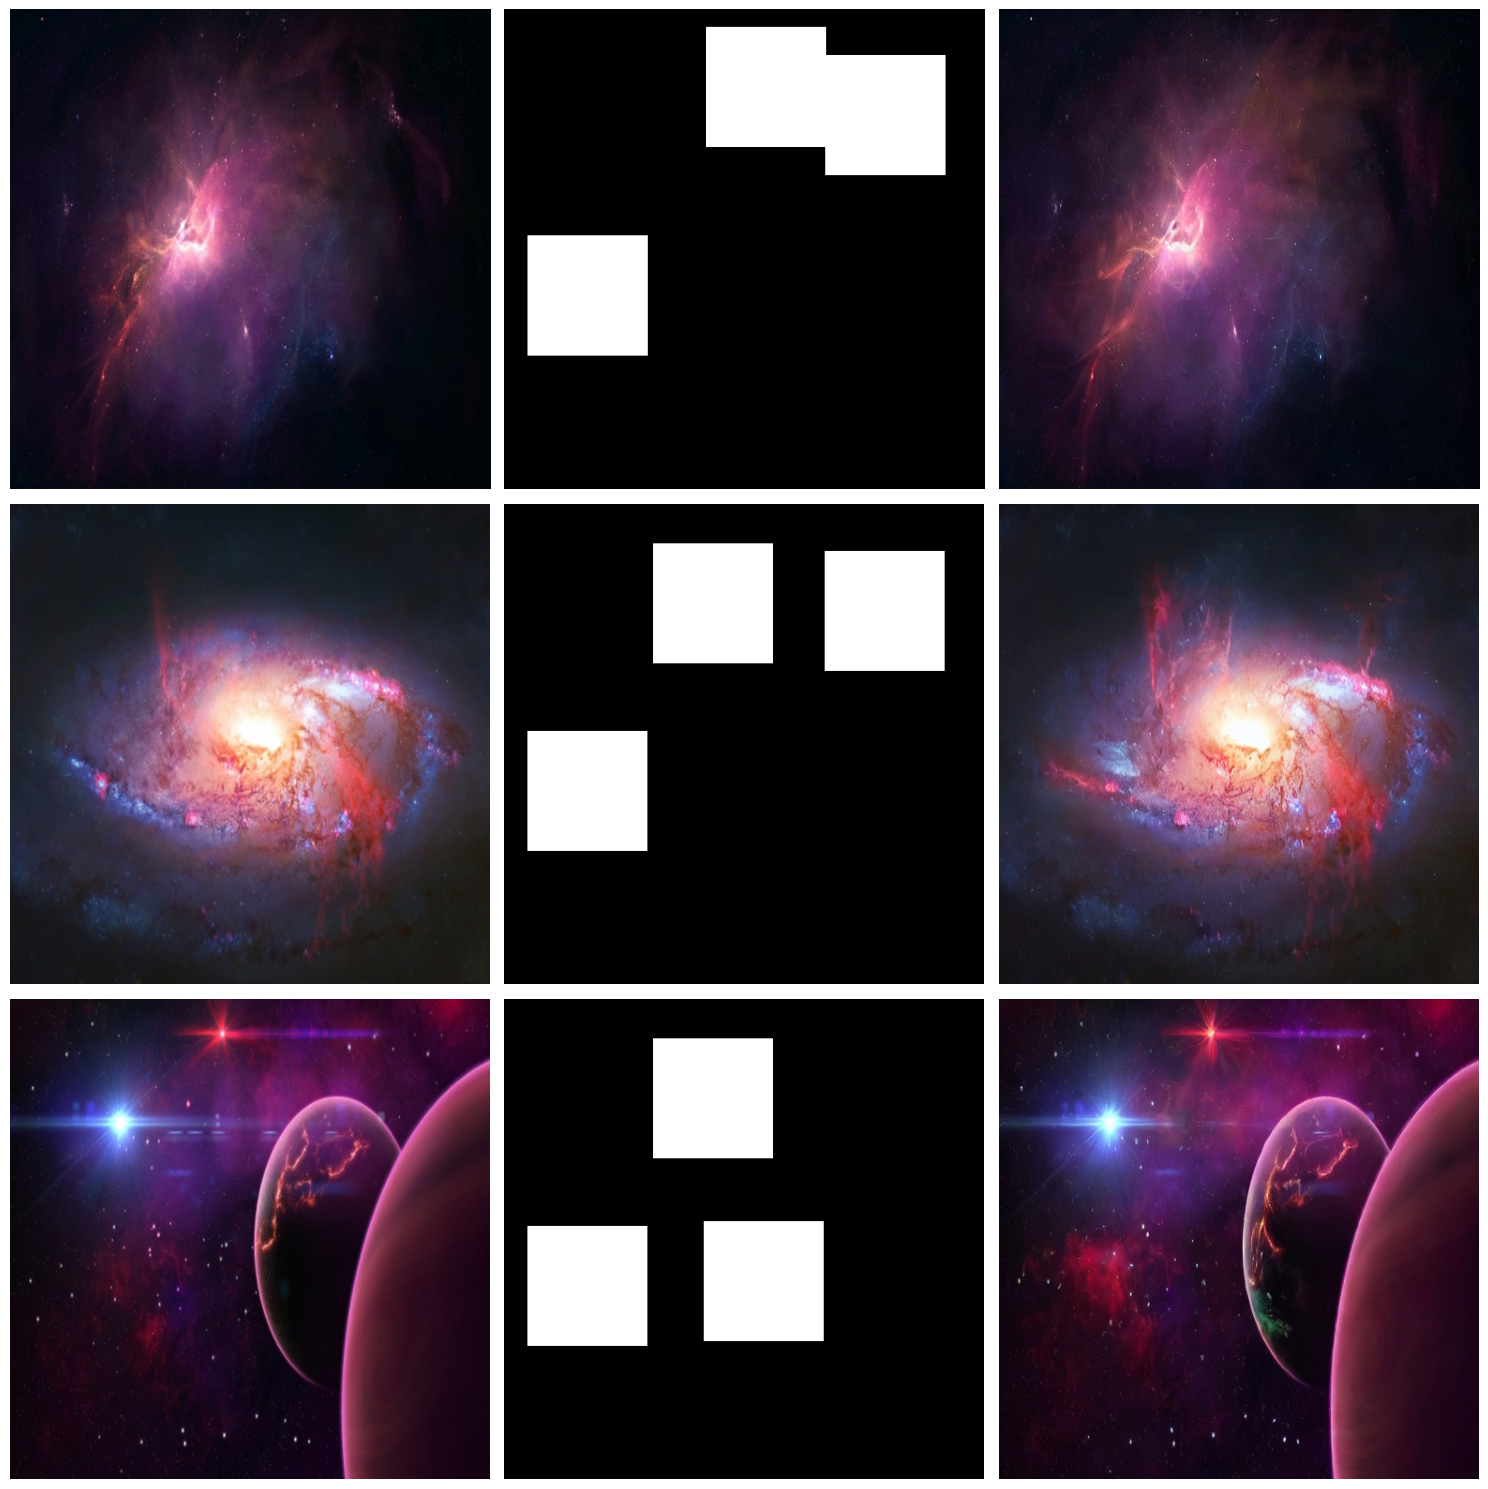

: 

In [ ]:
# Test inference on sample images
test_image_paths = [
    os.path.join(output_dir, "img", "1452899771.jpg"),
    os.path.join(output_dir, "img", "1507485125.jpg"),
    os.path.join(output_dir, "img", "1446082081.jpg")
]

transform = T.Compose([
    T.Resize((config.image_size, config.image_size)),
    T.ToTensor(),
])

# Visualize results: original | mask | inpainted
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for row, img_path in enumerate(test_image_paths):
    # Load and resize image
    image_pil = Image.open(img_path).convert("RGB")
    image_pil_resized = image_pil.resize((config.image_size, config.image_size), Image.Resampling.LANCZOS)
    image_tensor = transform(image_pil)
    
    # Generate mask
    mask_pil = generate_random_square_mask(config.image_size, num_squares=3, seed=row * 1000)
    
    image_np = image_tensor.permute(1, 2, 0).numpy()
    image_np = (image_np * 255).round().astype("uint8")
    
    mask_np = np.array(mask_pil)
    
    # Run inpainting
    with torch.no_grad():
        result = pipe(
            prompt="",
            image=image_pil_resized,
            mask_image=mask_pil,
            num_inference_steps=50,
            guidance_scale=7.5,
        )
        generated_image = result.images[0]
    
    # Display original image
    axes[row, 0].imshow(image_np)
    axes[row, 0].axis('off')
    
    # Display mask
    mask_rgb = np.stack([mask_np, mask_np, mask_np], axis=-1)
    axes[row, 1].imshow(mask_rgb)
    axes[row, 1].axis('off')
    
    # Display inpainted result
    axes[row, 2].imshow(generated_image)
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()